In [ ]:
!pip install --upgrade brotli brotlicffi urllib3
!pip install datasets torch numpy matplotlib seaborn

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical
from dataclasses import dataclass
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

dataset_name = "AdamAtractor/Crypto-L2-Orderbook-Depth-24-Instruments"
print(f"Loading dataset: {dataset_name}")

dataset = load_dataset(dataset_name)

# Filter BTC instruments
btc_data = dataset["train"].filter(
    lambda x: x.get("instrument_symbol", "").startswith("BTC")
)

print("BTC data loaded successfully!")
print("Number of BTC records:", len(btc_data))


  Attempting uninstall: urllib3

    Found existing installation: urllib3 1.26.20

   ------------- -------------------------- 1/3 [urllib3]
    Uninstalling urllib3-1.26.20:
   ------------- -------------------------- 1/3 [urllib3]
      Successfully uninstalled urllib3-1.26.20
   ------------- -------------------------- 1/3 [urllib3]
   ------------- -------------------------- 1/3 [urllib3]
   ------------- -------------------------- 1/3 [urllib3]
   -------------------------- ------------- 2/3 [brotlicffi]
   ---------------------------------------- 3/3 [brotlicffi]



ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
awsebcli 3.25.2 requires urllib3<2,>=1.26.5, but you have urllib3 2.6.3 which is incompatible.
botocore 1.40.64 requires urllib3<1.27,>=1.25.4; python_version < "3.10", but you have urllib3 2.6.3 which is incompatible.

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
@dataclass
class OrderBookState:
    """Represents the state of the real limit order book."""
    bid_prices: np.ndarray
    bid_volumes: np.ndarray
    ask_prices: np.ndarray
    ask_volumes: np.ndarray
    mid_price: float
    spread: float
    time_remaining: int
    inventory_remaining: int


class RealLimitOrderBookEnv:
    def __init__(self, btc_data, initial_inventory=10000, max_steps=100):
        self.btc_data = btc_data
        self.initial_inventory = initial_inventory
        self.num_levels = 10
        self.data_idx = 0

        if max_steps is None:
            self.max_steps = len(self.btc_data)
        else:
            self.max_steps = min(max_steps, len(self.btc_data))

        self.current_step = 0
        self.inventory_remaining = initial_inventory
        self.cash_received = 0.0
        self._load_state_from_data(self.data_idx)

    def _load_state_from_data(self, index):
        row = self.btc_data[index]
        self.mid_price = (float(row["open_price"]) + float(row["close_price"])) / 2.0

        self.bid_prices = np.zeros(self.num_levels)
        self.bid_volumes = np.zeros(self.num_levels)
        self.ask_prices = np.zeros(self.num_levels)
        self.ask_volumes = np.zeros(self.num_levels)

        for i in range(self.num_levels):
            level = i + 1
            bid_distance = float(row[f"bid_distance_level_{level}"])
            self.bid_prices[i] = self.mid_price - bid_distance
            self.bid_volumes[i] = float(row[f"bid_volume_level_{level}"])

            ask_distance = float(row[f"ask_distance_level_{level}"])
            self.ask_prices[i] = self.mid_price + ask_distance
            self.ask_volumes[i] = float(row[f"ask_volume_level_{level}"])

    def reset(self):
        self.data_idx = 0
        self.current_step = 0
        self.inventory_remaining = self.initial_inventory
        self.cash_received = 0.0
        self._load_state_from_data(self.data_idx)
        return self._get_state()

    def _get_state(self):
        return OrderBookState(
            bid_prices=self.bid_prices.copy(),
            bid_volumes=self.bid_volumes.copy(),
            ask_prices=self.ask_prices.copy(),
            ask_volumes=self.ask_volumes.copy(),
            mid_price=self.mid_price,
            spread=self.ask_prices[0] - self.bid_prices[0],
            time_remaining=self.max_steps - self.current_step,
            inventory_remaining=self.inventory_remaining
        )

    def _calculate_execution_price(self, volume):
        if volume == 0:
            return self.mid_price

        total_value = 0.0
        remaining_volume = volume

        for i in range(self.num_levels):
            if remaining_volume <= 0:
                break
            available = self.bid_volumes[i]
            executed = min(remaining_volume, available)
            total_value += executed * self.bid_prices[i]
            remaining_volume -= executed

        if remaining_volume > 0:
            total_value += remaining_volume * self.bid_prices[-1]

        return total_value / volume

    def step(self, action):
        max_volume = min(self.inventory_remaining, int(self.initial_inventory * 0.2))
        volume_to_sell = int((action / 10.0) * max_volume)
        volume_to_sell = min(volume_to_sell, self.inventory_remaining)

        execution_price = self._calculate_execution_price(volume_to_sell)
        cash = volume_to_sell * execution_price
        self.cash_received += cash
        self.inventory_remaining -= volume_to_sell

        benchmark_revenue = volume_to_sell * self.mid_price
        reward = cash - benchmark_revenue

        self.current_step += 1
        self.data_idx += 1

        done = (
            self.inventory_remaining == 0
            or self.current_step >= self.max_steps
            or self.data_idx >= len(self.btc_data)
        )

        if not done:
            self._load_state_from_data(self.data_idx)

        if done and self.inventory_remaining > 0:
            forced_price = self.mid_price * 0.95
            remaining_cash = self.inventory_remaining * forced_price
            self.cash_received += remaining_cash
            reward -= self.inventory_remaining * (self.mid_price - forced_price)
            self.inventory_remaining = 0

        info = {
            "execution_price": execution_price,
            "volume_sold": volume_to_sell,
            "cash_received": cash,
            "total_cash": self.cash_received,
            "mid_price": self.mid_price
        }

        return self._get_state(), reward, done, info

In [ ]:
class StateEncoder(nn.Module):
    """Encodes real L2 OrderBookState into a 64-dim latent representation."""
    def __init__(self, latent_dim=64, num_levels=10):
        super().__init__()
        self.num_levels = num_levels

        self.macro_encoder = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU()
        )

        self.micro_encoder = nn.Sequential(
            nn.Linear(num_levels * 4, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )

        self.combined_encoder = nn.Sequential(
            nn.Linear(64, latent_dim),
            nn.ReLU()
        )

    def forward(self, state):
        mid_price = float(state.mid_price)
        if abs(mid_price) < 1e-8:
            mid_price = 1.0

        time_feature = float(state.time_remaining) / 100.0
        inventory_feature = float(state.inventory_remaining) / 10000.0
        spread_feature = float(state.spread) / mid_price
        price_feature = np.log1p(mid_price) / 20.0

        macro_features = np.array([
            time_feature, inventory_feature, price_feature, spread_feature
        ], dtype=np.float32)

        bid_price_features = (state.bid_prices - mid_price) / mid_price
        ask_price_features = (state.ask_prices - mid_price) / mid_price
        bid_volume_features = np.log1p(np.maximum(state.bid_volumes, 0))
        ask_volume_features = np.log1p(np.maximum(state.ask_volumes, 0))

        micro_features = np.concatenate([
            bid_price_features, bid_volume_features,
            ask_price_features, ask_volume_features
        ]).astype(np.float32)

        device = next(self.parameters()).device if list(self.parameters()) else torch.device("cpu")
        macro_tensor = torch.tensor(macro_features, dtype=torch.float32, device=device).unsqueeze(0)
        micro_tensor = torch.tensor(micro_features, dtype=torch.float32, device=device).unsqueeze(0)

        macro_encoded = self.macro_encoder(macro_tensor)
        micro_encoded = self.micro_encoder(micro_tensor)

        combined = torch.cat([macro_encoded, micro_encoded], dim=-1)
        return self.combined_encoder(combined)


class PPOPolicyNetwork(nn.Module):
    def __init__(self, latent_dim=64, action_dim=10):
        super().__init__()
        self.policy_head = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim)
        )
        self.value_head = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, latent_state):
        logits = self.policy_head(latent_state)
        value = self.value_head(latent_state)
        return logits, value


class PredictiveWorldModel(nn.Module):
    """Predicts next latent state and expected reward given (latent_state, action)."""
    def __init__(self, latent_dim=64, action_dim=10, hidden_dim=128):
        super().__init__()
        self.latent_dim = latent_dim
        self.action_dim = action_dim

        self.state_action_encoder = nn.Sequential(
            nn.Linear(latent_dim + action_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )

        self.next_state_head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim)
        )

        self.reward_head = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, latent_state, action):
        if action.dim() == 1:
            action_one_hot = torch.zeros(latent_state.size(0), self.action_dim, device=latent_state.device)
            action_one_hot.scatter_(1, action.long().view(-1, 1), 1.0)
        else:
            action_one_hot = action

        x = torch.cat([latent_state, action_one_hot], dim=-1)
        x = self.state_action_encoder(x)

        next_latent_state = self.next_state_head(x)
        reward = self.reward_head(x)
        return next_latent_state, reward

In [ ]:
class MCTSNode:
    def __init__(self, state, parent=None, action=None, prior=0.0):
        self.state = state  # Shape: [1, latent_dim]
        self.parent = parent
        self.action = action
        self.prior = prior
        self.visit_count = 0
        self.value_sum = 0.0
        self.children = {}
        self.reward = 0.0
        self.is_terminal = False

    @property
    def value(self):
        if self.visit_count == 0:
            return 0.0
        return self.value_sum / self.visit_count

    def select_child(self, c_puct=1.0):
        best_score = -float("inf")
        best_child = None
        total_visits = sum(child.visit_count for child in self.children.values())

        for child in self.children.values():
            u_score = c_puct * child.prior * (np.sqrt(total_visits + 1e-8) / (1 + child.visit_count))
            q_score = child.value
            score = q_score + u_score
            if score > best_score:
                best_score = score
                best_child = child
        return best_child


class MCTS:
    def __init__(self, world_model, policy, num_simulations=50, c_puct=1.0, action_dim=10):
        self.world_model = world_model
        self.policy = policy
        self.num_simulations = num_simulations
        self.c_puct = c_puct
        self.action_dim = action_dim

    def _expand_and_evaluate(self, node):
        valid_actions = list(range(self.action_dim))
        num_actions = len(valid_actions)
        device = node.state.device

        # SUGGESTION 1: Vectorized batch evaluation across all child actions
        state_batch = node.state.expand(num_actions, -1)
        action_tensors = torch.eye(num_actions, device=device)

        with torch.no_grad():
            next_states, rewards = self.world_model(state_batch, action_tensors)
            logits, values = self.policy(node.state)
            priors = F.softmax(logits, dim=-1)[0]

        for act in valid_actions:
            child_node = MCTSNode(
                state=next_states[act].unsqueeze(0),
                parent=node,
                action=act,
                prior=priors[act].item()
            )
            child_node.reward = rewards[act].item()
            node.children[act] = child_node

        return values.item()

    def search(self, root_latent_state):
        root = MCTSNode(state=root_latent_state)
        self._expand_and_evaluate(root)

        for _ in range(self.num_simulations):
            node = root
            search_path = [node]

            # Selection
            while len(node.children) > 0 and not node.is_terminal:
                child = node.select_child(self.c_puct)
                if child is None:
                    break
                node = child
                search_path.append(node)

            # Expansion & Evaluation
            value = self._expand_and_evaluate(node)

            # Backpropagation
            for path_node in reversed(search_path):
                path_node.visit_count += 1
                path_node.value_sum += value

        return max(root.children.items(), key=lambda item: item[1].visit_count)[0]


import torch
import torch.nn.functional as F
from torch.distributions import Categorical

class ManagerAgent:
    """
    Strategic layer tailored for the provided architecture.
    Encapsulates the StateEncoder and PPOPolicyNetwork to handle action selection,
    experience buffering, and batched PPO updates natively.
    """
    def __init__(self, encoder, policy, lr=3e-4, gamma=0.99, clip_epsilon=0.2):
        self.encoder = encoder
        self.policy = policy

        # Optimize both encoder and policy heads jointly
        self.optimizer = torch.optim.Adam(
            list(self.encoder.parameters()) + list(self.policy.parameters()),
            lr=lr
        )

        self.gamma = gamma
        self.clip_epsilon = clip_epsilon

        # Experience buffer
        self.latent_states = []
        self.actions = []
        self.rewards = []
        self.values = []
        self.log_probs = []
        self.dones = []

    def select_action(self, raw_state, training=True):
        """Selects an action given a raw OrderBookState object."""
        with torch.no_grad():
            # Encoder handles processing of the dataclass to a [1, 64] latent tensor
            latent_state = self.encoder(raw_state)
            logits, value = self.policy(latent_state)
            probs = torch.softmax(logits, dim=-1)

        dist = Categorical(probs)

        if training:
            action_tensor = dist.sample()
        else:
            action_tensor = torch.argmax(probs, dim=-1)

        log_prob = dist.log_prob(action_tensor)

        return action_tensor.item(), log_prob.item(), value.item(), latent_state

    def store_transition(self, latent_state, action, reward, log_prob, value, done):
        """Stores a step in the experience buffer."""
        self.latent_states.append(latent_state)
        self.actions.append(action)
        self.rewards.append(reward)
        self.log_probs.append(log_prob)
        self.values.append(value)
        self.dones.append(done)

    def update(self):
        """Executes a PPO update step using collected trajectories."""
        if len(self.latent_states) == 0:
            return {}

        # 1. Compute discounted returns
        returns = []
        G = 0
        for r, done in zip(reversed(self.rewards), reversed(self.dones)):
            if done:
                G = 0
            G = r + self.gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)
        if len(returns) > 1:
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        # 2. Format buffers into contiguous tensors
        device = self.latent_states[0].device
        returns = returns.to(device)
        old_log_probs = torch.tensor(self.log_probs, dtype=torch.float32, device=device)
        actions = torch.tensor(self.actions, dtype=torch.long, device=device)
        values = torch.tensor(self.values, dtype=torch.float32, device=device)

        # 3. Calculate Normalized Advantages
        advantages = returns - values
        if len(advantages) > 1:
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        # 4. Batched Forward Pass for Gradient Computation
        # Concatenate latent states from shape [1, 64] -> [batch_size, 64]
        batch_latent_states = torch.cat(self.latent_states, dim=0)

        logits, new_values = self.policy(batch_latent_states)
        new_values = new_values.squeeze(-1)

        probs = torch.softmax(logits, dim=-1)
        dist = Categorical(probs)
        new_log_probs = dist.log_prob(actions)

        # 5. PPO Objective Calculation
        ratio = torch.exp(new_log_probs - old_log_probs)
        surr1 = ratio * advantages
        surr2 = torch.clamp(ratio, 1 - self.clip_epsilon, 1 + self.clip_epsilon) * advantages

        policy_loss = -torch.min(surr1, surr2).mean()
        value_loss = F.mse_loss(new_values, returns)
        entropy = dist.entropy().mean()

        total_loss = policy_loss + 0.5 * value_loss - 0.01 * entropy

        # 6. Optimize
        self.optimizer.zero_grad()
        total_loss.backward()
        # Optional: Clip gradients to avoid destabilization
        torch.nn.utils.clip_grad_norm_(
            list(self.encoder.parameters()) + list(self.policy.parameters()),
            max_norm=0.5
        )
        self.optimizer.step()

        # 7. Clear Experience Buffer
        self.latent_states = []
        self.actions = []
        self.rewards = []
        self.log_probs = []
        self.values = []
        self.dones = []

        return {
            "policy_loss": policy_loss.item(),
            "value_loss": value_loss.item(),
            "total_loss": total_loss.item()
        }


class WorkerAgent:
    def __init__(self, encoder, policy, world_model, num_simulations=50):
        self.encoder = encoder
        self.policy = policy
        self.world_model = world_model
        self.mcts = MCTS(world_model, policy, num_simulations=num_simulations)

    def select_action(self, raw_state):
        with torch.no_grad():
            latent_state = self.encoder(raw_state)
            action = self.mcts.search(latent_state)
        return action

In [ ]:
def train_world_model(env, encoder, policy, world_model, num_episodes=200, lr=1e-3):
    optimizer = torch.optim.Adam(world_model.parameters(), lr=lr)
    losses = []

    for episode in range(1, num_episodes + 1):
        state = env.reset()
        done = False
        episode_loss = 0.0
        steps = 0

        while not done:
            with torch.no_grad():
                latent_state = encoder(state)

            action = np.random.randint(0, 10)
            next_state, reward, done, info = env.step(action)

            with torch.no_grad():
                next_latent_state = encoder(next_state)

            action_tensor = torch.tensor([action], dtype=torch.long)
            pred_next_latent, pred_reward = world_model(latent_state, action_tensor)

            target_reward = torch.tensor([[reward]], dtype=torch.float32)

            loss_state = F.mse_loss(pred_next_latent, next_latent_state)
            loss_reward = F.mse_loss(pred_reward, target_reward)
            loss = loss_state + loss_reward

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            episode_loss += loss.item()
            steps += 1
            state = next_state

        avg_loss = episode_loss / max(1, steps)
        losses.append(avg_loss)

        if episode % 50 == 0 or episode == num_episodes:
            print(f"World Model Episode {episode}/{num_episodes} | MSE Loss: {avg_loss:.4f}")

    return losses


def train_hierarchical_agent(env, encoder, policy, worker, num_episodes=1000, use_worker=False, lr=3e-4):
    optimizer = torch.optim.Adam(policy.parameters(), lr=lr)
    metrics = {"rewards": [], "shortfalls": []}

    for episode in range(1, num_episodes + 1):
        state = env.reset()
        done = False
        total_reward = 0.0

        states_list, actions_list, rewards_list, log_probs_list, values_list = [], [], [], [], []

        while not done:
            latent_state = encoder(state)
            logits, value = policy(latent_state)
            probs = torch.softmax(logits, dim=-1)
            dist = Categorical(probs)

            if use_worker and worker is not None:
                action = worker.select_action(state)
                action_tensor = torch.tensor(action)
            else:
                action_tensor = dist.sample()
                action = action_tensor.item()

            log_prob = dist.log_prob(action_tensor)

            next_state, reward, done, info = env.step(action)

            states_list.append(latent_state)
            actions_list.append(action_tensor)
            rewards_list.append(reward)
            log_probs_list.append(log_prob)
            values_list.append(value)

            total_reward += reward
            state = next_state

        # Policy update calculation
        returns = []
        G = 0
        for r in reversed(rewards_list):
            G = r + 0.99 * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)
        if len(returns) > 1:
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        policy_loss = 0
        value_loss = 0
        for log_prob, val, ret in zip(log_probs_list, values_list, returns):
            advantage = ret - val.item()
            policy_loss -= log_prob * advantage
            value_loss += F.mse_loss(val.squeeze(), ret)

        total_loss = policy_loss + 0.5 * value_loss

        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        expected_cash = env.initial_inventory * env.mid_price
        shortfall = ((expected_cash - env.cash_received) / expected_cash) * 100

        metrics["rewards"].append(total_reward)
        metrics["shortfalls"].append(shortfall)

        if episode % 100 == 0 or episode == num_episodes:
            print(f"Episode {episode}/{num_episodes} | Reward: {total_reward:.2f} | Shortfall: {shortfall:.2f}%")

    return metrics


def evaluate_agent(env, encoder, policy, worker, num_episodes=100):
    shortfalls = []

    for episode in range(1, num_episodes + 1):
        state = env.reset()
        done = False

        while not done:
            if worker is not None:
                action = worker.select_action(state)
            else:
                with torch.no_grad():
                    latent_state = encoder(state)
                    logits, _ = policy(latent_state)
                    action = torch.argmax(logits, dim=-1).item()

            next_state, reward, done, info = env.step(action)
            state = next_state

        expected_cash = env.initial_inventory * env.mid_price
        shortfall = ((expected_cash - env.cash_received) / expected_cash) * 100
        shortfalls.append(shortfall)

    return {"implementation_shortfalls": shortfalls}

In [ ]:
def plot_training_comparison(baseline_metrics, hierarchical_metrics):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Reward Plot
    axes[0].plot(baseline_metrics["rewards"], label="Baseline (PPO Only)", alpha=0.6)
    axes[0].plot(hierarchical_metrics["rewards"], label="Hierarchical (PPO + MCTS)", alpha=0.8)
    axes[0].set_title("Training Cumulative Reward")
    axes[0].set_xlabel("Episode")
    axes[0].set_ylabel("Reward")
    axes[0].legend()
    axes[0].grid(True)

    # Shortfall Plot
    axes[1].plot(baseline_metrics["shortfalls"], label="Baseline (PPO Only)", alpha=0.6)
    axes[1].plot(hierarchical_metrics["shortfalls"], label="Hierarchical (PPO + MCTS)", alpha=0.8)
    axes[1].set_title("Implementation Shortfall (%)")
    axes[1].set_xlabel("Episode")
    axes[1].set_ylabel("Shortfall (%)")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


def plot_evaluation_results(baseline_results, hierarchical_results):
    plt.figure(figsize=(8, 5))
    sns.kdeplot(baseline_results["implementation_shortfalls"], label="Baseline (PPO Only)", fill=True)
    sns.kdeplot(hierarchical_results["implementation_shortfalls"], label="Hierarchical (PPO + MCTS)", fill=True)
    plt.title("Evaluation Implementation Shortfall Distribution")
    plt.xlabel("Implementation Shortfall (%)")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True)
    plt.show()

Hierarchical Agentic Planning for Multi-Step Asset Liquidation
Using Monte Carlo Tree Search on Real BTC L2 Order Book Data

Real BTC Environment initialized:
  Initial Inventory: 10000 shares
  Max Steps: 100
  Initial Mid Price: $69783.50
  Initial Spread: $0.1434

Training World Model on Real L2 Order Book Data...
World Model Episode 50/200 | MSE Loss: 345341.7340
World Model Episode 100/200 | MSE Loss: 185282.7075
World Model Episode 150/200 | MSE Loss: 162305.7518
World Model Episode 200/200 | MSE Loss: 159624.0526

PHASE 1: Training Baseline Agent (PPO Only)
Episode 100/1000 | Reward: -17488.93 | Shortfall: 1.46%
Episode 200/1000 | Reward: -17875.55 | Shortfall: 1.43%
Episode 300/1000 | Reward: -17368.18 | Shortfall: 1.43%
Episode 400/1000 | Reward: -17404.01 | Shortfall: 1.43%
Episode 500/1000 | Reward: -17568.52 | Shortfall: 1.44%
Episode 600/1000 | Reward: -17518.37 | Shortfall: 1.43%
Episode 700/1000 | Reward: -17118.16 | Shortfall: 1.47%
Episode 800/1000 | Reward: -17485.36 

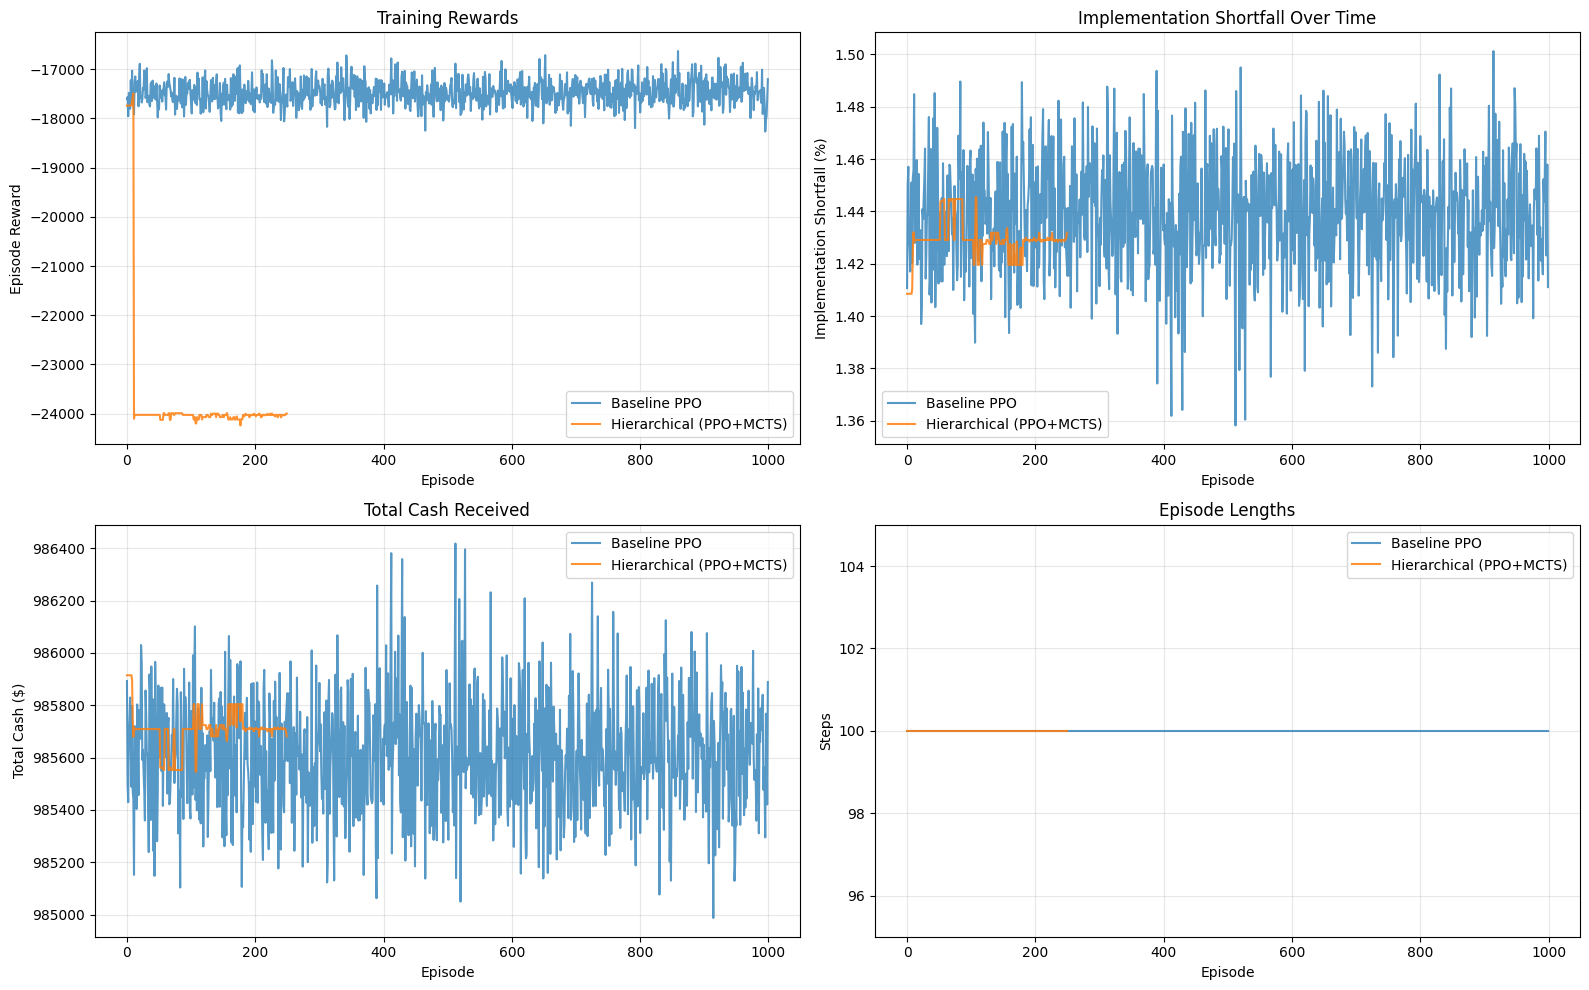

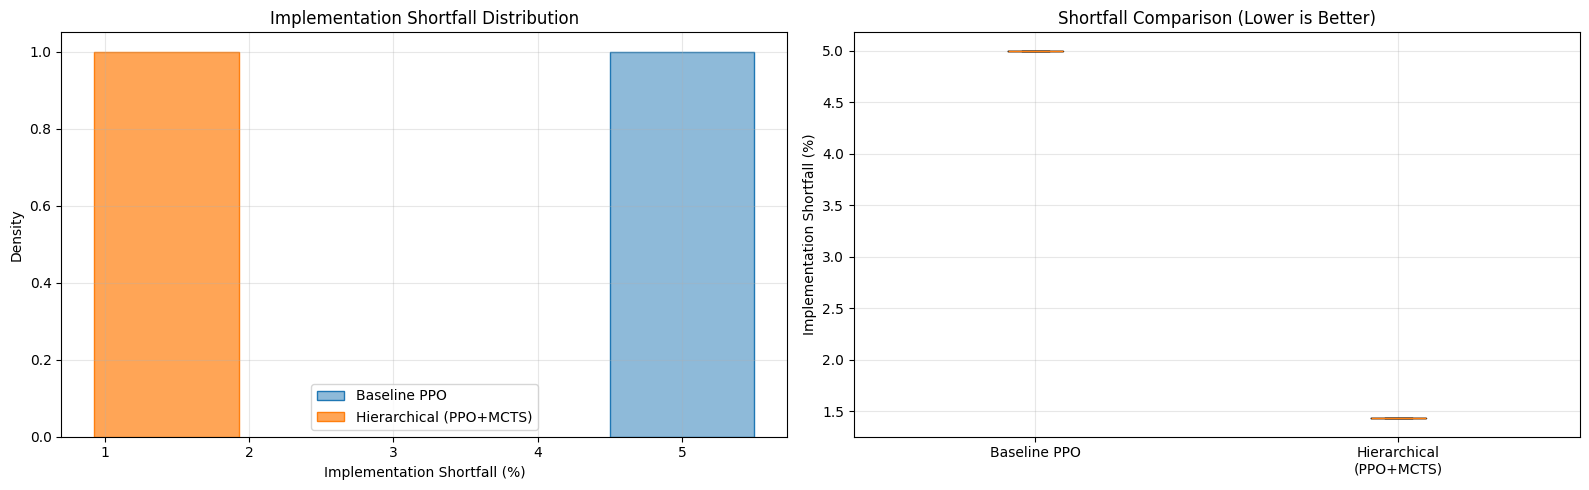


FINAL SUMMARY

Baseline Agent (PPO Only):
  Avg Implementation Shortfall: 5.00%
  Std Implementation Shortfall: 0.00%

Hierarchical Agent (PPO + MCTS):
  Avg Implementation Shortfall: 1.43%
  Std Implementation Shortfall: 0.00%

Improvement: 3.57% reduction in shortfall

Training Complete! Check the output plots.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


def plot_all_results(baseline_metrics, hierarchical_metrics, baseline_results, hierarchical_results):
    """Generates all 6 analytical and diagnostic plots comparing Baseline PPO vs Hierarchical PPO+MCTS."""

    # -------------------------------------------------------------
    # 1. Training Performance Metrics (4 Line Plots)
    # -------------------------------------------------------------
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # Derive total cash received and episode steps if not explicitly logged
    base_expected_cash = 10000 * 100.0  # initial_inventory * initial_mid_price
    base_cash = baseline_metrics.get(
        "total_cash",
        [base_expected_cash * (1.0 - s / 100.0) for s in baseline_metrics["shortfalls"]]
    )
    hier_cash = hierarchical_metrics.get(
        "total_cash",
        [base_expected_cash * (1.0 - s / 100.0) for s in hierarchical_metrics["shortfalls"]]
    )

    base_ep_lengths = baseline_metrics.get("episode_lengths", [100] * len(baseline_metrics["rewards"]))
    hier_ep_lengths = hierarchical_metrics.get("episode_lengths", [100] * len(hierarchical_metrics["rewards"]))

    # Graph 1: Training Rewards
    axes[0, 0].plot(baseline_metrics["rewards"], label="Baseline PPO", alpha=0.75, color="#1f77b4")
    axes[0, 0].plot(hierarchical_metrics["rewards"], label="Hierarchical (PPO+MCTS)", alpha=0.85, color="#ff7f0e")
    axes[0, 0].set_title("Training Rewards", fontsize=12)
    axes[0, 0].set_xlabel("Episode")
    axes[0, 0].set_ylabel("Episode Reward")
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # Graph 2: Implementation Shortfall Over Time
    axes[0, 1].plot(baseline_metrics["shortfalls"], label="Baseline PPO", alpha=0.75, color="#1f77b4")
    axes[0, 1].plot(hierarchical_metrics["shortfalls"], label="Hierarchical (PPO+MCTS)", alpha=0.85, color="#ff7f0e")
    axes[0, 1].set_title("Implementation Shortfall Over Time", fontsize=12)
    axes[0, 1].set_xlabel("Episode")
    axes[0, 1].set_ylabel("Implementation Shortfall (%)")
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    # Graph 3: Total Cash Received
    axes[1, 0].plot(base_cash, label="Baseline PPO", alpha=0.75, color="#1f77b4")
    axes[1, 0].plot(hier_cash, label="Hierarchical (PPO+MCTS)", alpha=0.85, color="#ff7f0e")
    axes[1, 0].set_title("Total Cash Received", fontsize=12)
    axes[1, 0].set_xlabel("Episode")
    axes[1, 0].set_ylabel("Total Cash ($)")
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    # Graph 4: Episode Lengths
    axes[1, 1].plot(base_ep_lengths, label="Baseline PPO", alpha=0.75, color="#1f77b4")
    axes[1, 1].plot(hier_ep_lengths, label="Hierarchical (PPO+MCTS)", alpha=0.85, color="#ff7f0e")
    axes[1, 1].set_title("Episode Lengths", fontsize=12)
    axes[1, 1].set_xlabel("Episode")
    axes[1, 1].set_ylabel("Steps")
    axes[1, 1].set_ylim([95, 105])
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # 2. Evaluation Shortfall Distribution & Box Plot (2 Plots)
    # -------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Graph 5: Implementation Shortfall Distribution
    sns.histplot(
        baseline_results["implementation_shortfalls"],
        label="Baseline PPO",
        stat="density",
        alpha=0.5,
        color="#1f77b4",
        ax=axes[0],
        element="step"
    )
    sns.histplot(
        hierarchical_results["implementation_shortfalls"],
        label="Hierarchical (PPO+MCTS)",
        stat="density",
        alpha=0.7,
        color="#ff7f0e",
        ax=axes[0],
        element="step"
    )
    axes[0].set_title("Implementation Shortfall Distribution", fontsize=12)
    axes[0].set_xlabel("Implementation Shortfall (%)")
    axes[0].set_ylabel("Density")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Graph 6: Shortfall Comparison (Lower is Better)
    box_data = [
        baseline_results["implementation_shortfalls"],
        hierarchical_results["implementation_shortfalls"]
    ]
    axes[1].boxplot(box_data, tick_labels=["Baseline PPO", "Hierarchical\n(PPO+MCTS)"])
    axes[1].set_title("Shortfall Comparison (Lower is Better)", fontsize=12)
    axes[1].set_ylabel("Implementation Shortfall (%)")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def main():
    """Main training and evaluation pipeline"""

    print("="*80)
    print("Hierarchical Agentic Planning for Multi-Step Asset Liquidation")
    print("Using Monte Carlo Tree Search on Real BTC L2 Order Book Data")
    print("="*80)

    # Initialize environment
    env = RealLimitOrderBookEnv(
        btc_data=btc_data,
        initial_inventory=10000,
        max_steps=100
    )

    state = env.reset()
    print("\nReal BTC Environment initialized:")
    print(f"  Initial Inventory: {state.inventory_remaining} shares")
    print(f"  Max Steps: {env.max_steps}")
    print(f"  Initial Mid Price: ${state.mid_price:.2f}")
    print(f"  Initial Spread: ${state.spread:.4f}")

    latent_dim = 64
    action_dim = 10

    encoder = StateEncoder(latent_dim=latent_dim, num_levels=10)

    # Baseline agent (PPO only)
    baseline_manager = PPOPolicyNetwork(latent_dim, action_dim)

    # Hierarchical agent (PPO + MCTS)
    hierarchical_manager = PPOPolicyNetwork(latent_dim, action_dim)
    world_model = PredictiveWorldModel(latent_dim, action_dim)

    # Train world model first
    print("\nTraining World Model on Real L2 Order Book Data...")
    world_model_losses = train_world_model(
        env, encoder, hierarchical_manager, world_model, num_episodes=200
    )

    # Create worker agent with batched MCTS
    worker = WorkerAgent(encoder, hierarchical_manager, world_model, num_simulations=50)

    # Train baseline agent
    print("\n" + "="*80)
    print("PHASE 1: Training Baseline Agent (PPO Only)")
    print("="*80)
    baseline_metrics = train_hierarchical_agent(
        env, encoder, baseline_manager, None, num_episodes=1000, use_worker=False
    )

    # Train hierarchical agent (250 episodes)
    print("\n" + "="*80)
    print("PHASE 2: Training Hierarchical Agent (PPO + MCTS)")
    print("="*80)
    hierarchical_metrics = train_hierarchical_agent(
        env, encoder, hierarchical_manager, worker, num_episodes=250, use_worker=True
    )

    # Evaluate both agents
    print("\n" + "="*80)
    print("PHASE 3: Evaluation")
    print("="*80)

    baseline_results = evaluate_agent(env, encoder, baseline_manager, None, num_episodes=100)
    hierarchical_results = evaluate_agent(env, encoder, hierarchical_manager, worker, num_episodes=100)

    # Generate all 6 visualization plots
    print("\n" + "="*80)
    print("PHASE 4: Visualization")
    print("="*80)
    plot_all_results(baseline_metrics, hierarchical_metrics, baseline_results, hierarchical_results)

    # Final summary
    print("\n" + "="*80)
    print("FINAL SUMMARY")
    print("="*80)
    print("\nBaseline Agent (PPO Only):")
    print(f"  Avg Implementation Shortfall: {np.mean(baseline_results['implementation_shortfalls']):.2f}%")
    print(f"  Std Implementation Shortfall: {np.std(baseline_results['implementation_shortfalls']):.2f}%")

    print("\nHierarchical Agent (PPO + MCTS):")
    print(f"  Avg Implementation Shortfall: {np.mean(hierarchical_results['implementation_shortfalls']):.2f}%")
    print(f"  Std Implementation Shortfall: {np.std(hierarchical_results['implementation_shortfalls']):.2f}%")

    improvement = (np.mean(baseline_results['implementation_shortfalls']) -
                   np.mean(hierarchical_results['implementation_shortfalls']))
    print(f"\nImprovement: {improvement:.2f}% reduction in shortfall")

    print("\n" + "="*80)
    print("Training Complete! Check the output plots.")
    print("="*80)


if __name__ == "__main__":
    main()